# T10. Limpieza de los viajes

**Objetivo.** Decidir qué viajes del CSV original entran en el análisis con umbrales justificados con datos. No se borra ningún viaje: los no válidos quedan con `elegible = False` y sus reglas incumplidas en `motivo`.

**Valor para el proyecto.** Todas las fases (matrices OD, estaciones, flota, consumo y recarga) parten de estos viajes. Si se cuelan desbloqueos sin viaje o viajes sin cerrar, inflan la demanda y la energía; si se quita demasiado, la red se diseña para menos demanda de la real.

Los umbrales están en `config.yaml` (`limpieza`). Se revisan con el periodo de ajuste (1–21/02) y se aplican igual a la semana reservada (22–28/02). Este notebook genera `datos/procesados/viajes_limpios.parquet`, las tablas `T10_*` de `resultados/tablas/exploracion/`, las figuras `T10_*` y los datos de la web.

In [1]:
import numpy as np
import pandas as pd
import h3
from IPython.display import display

from comun import limpieza
from comun.config import cargar_config, carpeta_tablas, ruta
from comun.datos import generar_viajes_limpios
from comun.figuras import guardar_figura, plt
from comun.web import exportar

TEMA, FASE = "exploracion", "fase0"
TABLAS = carpeta_tablas(TEMA)
CFG = cargar_config()
U = limpieza.umbrales()

def tabla_indicadores(filas):
    # Tabla indicador/valor que conserva los enteros como enteros en el CSV.
    return pd.DataFrame({"indicador": [k for k, _ in filas],
                         "valor": pd.Series([v for _, v in filas], dtype=object)})

## 1. Comprobaciones estructurales y embudo de limpieza

**Qué queremos ver.** Si el CSV tiene errores de estructura (nulos, duplicados, duraciones, velocidades o precios que no cuadran, puntos fuera de Roma, viajes solapados del mismo patinete) y cuántos viajes quita cada regla aplicada en orden.

**Por qué importa.** Si los datos son coherentes, solo hay que decidir umbrales de comportamiento. La tabla de embudo es la que va a la memoria para que se pueda auditar cada viaje excluido.

In [2]:
viajes, embudo, recuento = generar_viajes_limpios()
embudo.to_csv(TABLAS / "T10_embudo.csv", index=False)
recuento.to_csv(TABLAS / "T10_recuento_motivos.csv", index=False)

periodos = (viajes.groupby("periodo")
            .agg(viajes=("trip_id", "size"), elegibles=("elegible", "sum"))
            .reset_index())
periodos["porcentaje_elegibles"] = (100 * periodos["elegibles"] / periodos["viajes"]).round(2)
periodos.to_csv(TABLAS / "T10_viajes_por_periodo.csv", index=False)

exportar(FASE, "t10_embudo", {"pasos": embudo, "recuento": recuento, "periodos": periodos})
display(embudo, recuento, periodos)

,paso,regla,descripcion,excluidos,quedan
0,0,inicial,Viajes del CSV original,0,25186
1,1,nulos,Algún campo vacío,0,25186
2,2,duplicado,Mismo patinete y misma salida que otro viaje,0,25186
3,3,tiempos_incoherentes,tsD - tsO distinto de tt (±1 s) o tt <= 0,0,25186
4,4,velocidad_incoherente,"vel distinta de 3,6·dis/tt (±0.01 km/h)",0,25186
5,5,precio_incoherente,Precio distinto de la tarifa (±0.01 €),0,25186
6,6,fuera_de_zona,Algún extremo fuera del rectángulo de servicio,0,25186
7,7,solape,Empieza antes de que acabe el viaje anterior d...,0,25186
8,8,tt_largo,Duración > 7200 s,122,25064
9,9,vel_alta,Velocidad > 25 km/h,2,25062


,motivo,viajes,unico_motivo,porcentaje
0,nulos,0,0,0.00
1,duplicado,0,0,0.00
2,tiempos_incoherentes,0,0,0.00
3,velocidad_incoherente,0,0,0.00
4,precio_incoherente,0,0,0.00
5,fuera_de_zona,0,0,0.00
6,solape,0,0,0.00
7,tt_largo,122,12,0.48
8,vel_alta,2,1,0.01
9,tt_corto,950,157,3.77


,periodo,viajes,elegibles,porcentaje_elegibles
0,ajuste,18004,16710,92.81
1,reservada,7182,6582,91.65


**Conclusiones.**

- Los datos son estructuralmente limpios: ninguna de las siete comprobaciones estructurales falla. El precio es exactamente `1 € + 0,15 €/min` y la velocidad `3,6 · dis / tt` en todos los viajes.
- Solo se excluyen viajes por comportamiento: 122 de más de 2 h, 2 de más de 25 km/h, 949 de menos de 60 s, 596 más de menos de 100 m y 225 más de menos de 2 km/h.
- Quedan **23 292 viajes elegibles (92,5 %)**: 16 710 en el ajuste (92,8 %) y 6 582 en la semana reservada (91,7 %). Los dos periodos pierden una proporción parecida, así que la limpieza no sesga la validación.

## 2. Distribuciones de duración, distancia y velocidad con los umbrales

**Qué queremos ver.** Dónde caen los umbrales respecto a la forma de cada distribución: si cortan colas o picos anómalos o si se meten en la parte central de los viajes normales.

**Por qué importa.** Un umbral es defendible si separa dos poblaciones distintas (desbloqueos frente a viajes, viajes cerrados frente a olvidados). Si cortara por la mitad de la distribución, estaríamos quitando demanda real.

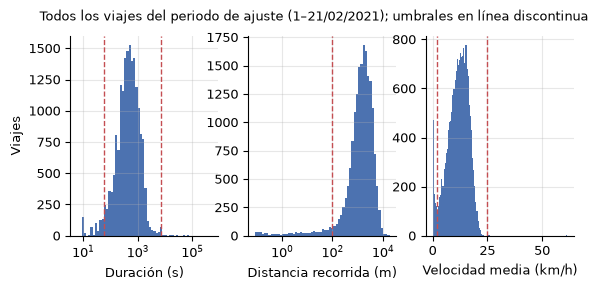

In [3]:
ajuste = viajes[viajes["periodo"] == "ajuste"]
paneles = {
    "tt_s": ("Duración (s)", [U["tt_min_s"], U["tt_max_s"]], "log"),
    "dis_m": ("Distancia recorrida (m)", [U["dis_min_m"]], "log"),
    "vel_kmh": ("Velocidad media (km/h)", [U["vel_min_kmh"], U["vel_max_kmh"]], "lineal"),
}
histogramas = {}
fig, ejes = plt.subplots(1, 3, figsize=(6.5, 2.6))
for eje, (col, (etiqueta, lineas, escala)) in zip(ejes, paneles.items()):
    if escala == "log":
        valores = ajuste[col][ajuste[col] > 0]
        bordes = np.logspace(np.log10(valores.min()), np.log10(valores.max()), 61)
    else:
        valores = ajuste[col]
        bordes = np.arange(0, valores.max() + 0.5, 0.5)
    cuentas, _ = np.histogram(valores, bins=bordes)
    histogramas[col] = {"etiqueta": etiqueta, "escala": escala, "bordes": bordes.round(4),
                        "cuentas": cuentas, "umbrales": lineas,
                        "fuera_de_escala": int(len(ajuste) - cuentas.sum())}
    eje.stairs(cuentas, bordes, fill=True, color="#4C72B0")
    if escala == "log":
        eje.set_xscale("log")
    for u in lineas:
        eje.axvline(u, color="#C44E52", lw=1, ls="--")
    eje.set_xlabel(etiqueta)
ejes[0].set_ylabel("Viajes")
fig.suptitle("Todos los viajes del periodo de ajuste (1–21/02/2021); umbrales en línea discontinua", fontsize=9)
guardar_figura(fig, TEMA, "T10_umbrales")
exportar(FASE, "t10_histogramas", {"n_viajes": len(ajuste), "variables": histogramas})

**Conclusiones.**

- Duración: casi todos los viajes duran entre 2 y 30 minutos. Los 60 s dejan fuera un grupo pequeño de desbloqueos de pocos segundos y las 2 h, una cola larga y casi plana.
- Distancia: por debajo de 100 m hay una cola larga y plana que llega a menos de 1 m (patinetes que casi no se mueven). La distribución principal empieza a subir justo a partir del corte de 100 m.
- Velocidad: hay un pico junto a 0 km/h y un valle hacia los 2 km/h antes de la distribución principal (mediana de unos 12 km/h). El límite de 25 km/h coincide con la velocidad máxima del patinete y solo afecta a 2 viajes.

## 3. Los viajes casi parados

**Qué queremos ver.** Qué son los ~1 000 viajes del pico de velocidad cercana a 0 y si las reglas de duración y distancia ya los quitan o hace falta una regla propia.

**Por qué importa.** Un viaje a 1 km/h que recorre 500 m ocupa el patinete durante media hora. En la simulación de flota inflaría el tiempo de uso y en la de consumo no cambiaría la energía, así que hay que decidir explícitamente qué hacer con ellos.

In [4]:
lentos = viajes[viajes["vel_kmh"] < 1]
solo_vel_baja = viajes[viajes["motivo"] == "vel_baja"]
resumen_lentos = tabla_indicadores([
    ("viajes con velocidad < 1 km/h", len(lentos)),
    ("  excluidos también por otras reglas", int((lentos["motivo"] != "vel_baja").sum())),
    ("  que solo excluye vel_baja", int((lentos["motivo"] == "vel_baja").sum())),
    ("viajes que solo excluye vel_baja (< 2 km/h)", len(solo_vel_baja)),
    ("  distancia mediana (m)", round(solo_vel_baja["dis_m"].median(), 1)),
    ("  duración mediana (min)", round(solo_vel_baja["tt_s"].median() / 60, 1)),
    ("  porcentaje que dura más de 20 min", round(100 * (solo_vel_baja["tt_s"] > 1200).mean(), 1)),
])
resumen_lentos.to_csv(TABLAS / "T10_viajes_lentos.csv", index=False)
exportar(FASE, "t10_lentos", resumen_lentos)
display(resumen_lentos)

,indicador,valor
0,viajes con velocidad < 1 km/h,976
1,excluidos también por otras reglas,894
2,que solo excluye vel_baja,82
3,viajes que solo excluye vel_baja (< 2 km/h),225
4,distancia mediana (m),532.7
5,duración mediana (min),35.5
6,porcentaje que dura más de 20 min,63.6


**Conclusiones.**

- El pico de ~1 000 viajes por debajo de 1 km/h son desbloqueos sin recorrido: 894 de los 976 ya caen por duración o distancia.
- Los que solo excluye la regla nueva `vel_baja` (225) recorren distancias normales (mediana de 533 m) pero duran mucho (mediana de 35,5 min). Son patinetes que no se cerraron a tiempo o que se llevaron a mano, no desplazamientos en patinete.
- Se añade `vel_baja` con umbral de 2 km/h, en el valle del histograma. Cuesta el 1 % de la demanda y se comprueba en el apartado 5 que no cambia las conclusiones.

## 4. Sensibilidad de cada umbral

**Qué queremos ver.** Cuántos viajes del periodo de ajuste excluiría cada umbral por sí solo al moverlo, y si el valor elegido está en una zona estable o en una pendiente fuerte.

**Por qué importa.** Si un pequeño cambio de umbral moviera muchos viajes, la decisión sería frágil y habría que justificarla mejor o revisar su efecto en los resultados.

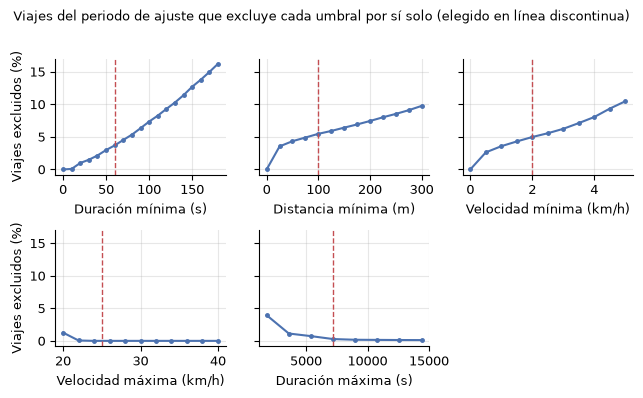

parametro,dis_min_m,tt_max_s,tt_min_s,vel_max_kmh,vel_min_kmh
umbral,,,,,
0.0,0.00,NaN,0.00,NaN,0.00
0.5,NaN,NaN,NaN,NaN,2.62
1.0,NaN,NaN,NaN,NaN,3.57
1.5,NaN,NaN,NaN,NaN,4.30
2.0,NaN,NaN,NaN,NaN,4.98
2.5,NaN,NaN,NaN,NaN,5.56
3.0,NaN,NaN,NaN,NaN,6.24
3.5,NaN,NaN,NaN,NaN,7.12
4.0,NaN,NaN,NaN,NaN,8.05


In [5]:
BARRIDOS = {
    "tt_min_s": ("tt_s", "menor", list(range(0, 181, 10)), "Duración mínima (s)"),
    "dis_min_m": ("dis_m", "menor", list(range(0, 301, 25)), "Distancia mínima (m)"),
    "vel_min_kmh": ("vel_kmh", "menor", [x / 2 for x in range(0, 11)], "Velocidad mínima (km/h)"),
    "vel_max_kmh": ("vel_kmh", "mayor", list(range(20, 41, 2)), "Velocidad máxima (km/h)"),
    "tt_max_s": ("tt_s", "mayor", list(range(1800, 14401, 1800)), "Duración máxima (s)"),
}
filas = []
for parametro, (col, sentido, valores, _) in BARRIDOS.items():
    for v in valores:
        fuera = (ajuste[col] < v) if sentido == "menor" else (ajuste[col] > v)
        filas.append({"parametro": parametro, "umbral": v, "excluidos": int(fuera.sum()),
                      "porcentaje": round(100 * fuera.mean(), 2)})
sens = pd.DataFrame(filas)
sens.to_csv(TABLAS / "T10_sensibilidad_umbrales.csv", index=False)

fig, ejes = plt.subplots(2, 3, figsize=(6.5, 4.0), sharey=True)
ejes = ejes.ravel()
for eje, (parametro, (_, _, _, etiqueta)) in zip(ejes, BARRIDOS.items()):
    t = sens[sens["parametro"] == parametro]
    eje.plot(t["umbral"], t["porcentaje"], marker="o", ms=2.5, color="#4C72B0")
    eje.axvline(U[parametro], color="#C44E52", lw=1, ls="--")
    eje.set_xlabel(etiqueta)
ejes[-1].set_visible(False)
for eje in ejes[::3]:
    eje.set_ylabel("Viajes excluidos (%)")
fig.suptitle("Viajes del periodo de ajuste que excluye cada umbral por sí solo (elegido en línea discontinua)", fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.96))
guardar_figura(fig, TEMA, "T10_sensibilidad_umbrales")

exportar(FASE, "t10_sensibilidad", {
    p: {"etiqueta": etiqueta, "elegido": U[p], "umbral": sens.loc[sens.parametro == p, "umbral"],
        "excluidos": sens.loc[sens.parametro == p, "excluidos"],
        "porcentaje": sens.loc[sens.parametro == p, "porcentaje"]}
    for p, (_, _, _, etiqueta) in BARRIDOS.items()
})
display(sens.pivot_table(index="umbral", columns="parametro", values="porcentaje"))

**Conclusiones.**

- Duración mínima: la curva sube sin codo. 60 s es el criterio natural de "menos de un minuto no es un viaje" y excluye por sí solo el 3,7 %.
- Distancia mínima: el salto está por debajo de 25 m (3,5 %); a partir de ahí la curva es casi lineal, así que 100 m o 50 m cambian poco.
- Velocidad mínima: la curva sube suave; 2 km/h excluye el 5,0 % por sí solo, pero casi todos ya caen por las reglas anteriores.
- Velocidad y duración máximas: las curvas se aplanan antes del umbral elegido (25 km/h y 2 h), así que son decisiones estables.

## 5. Limpieza permisiva frente a la principal

**Qué queremos ver.** Si una limpieza menos restrictiva (30 s, 50 m, sin velocidad mínima, 30 km/h y 3 h) cambia los indicadores que usarán las fases siguientes: volumen, distancias, duraciones, kilómetros, energía y concentración espacial.

**Por qué importa.** Es la prueba de robustez de la limpieza. Si los indicadores apenas cambian, las conclusiones del proyecto no dependen de los umbrales y se puede decir en la memoria.

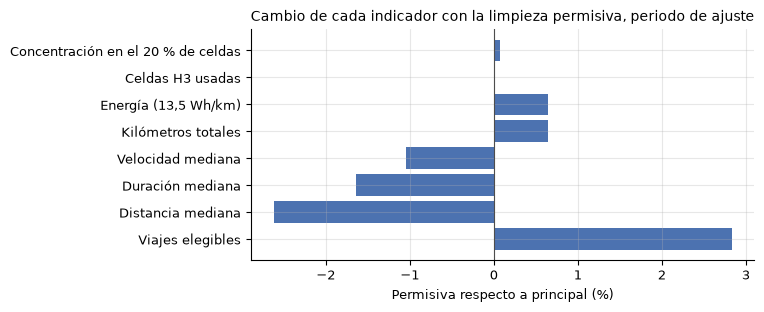

,limpieza,periodo,viajes_elegibles,porcentaje_elegibles,dis_m_mediana,tt_s_mediana,vel_kmh_mediana,km_totales,energia_kwh_13_5,celdas_h3_res8,extremos_en_20pc_celdas_pc
0,principal,ajuste,16710,92.81,1618.6,489.0,12.48,34314.4,463.2,111,56.90
1,principal,reservada,6582,91.65,1671.8,499.0,12.50,14013.4,189.2,108,54.99
2,permisiva,ajuste,17183,95.44,1576.2,481.0,12.35,34533.0,466.2,111,56.94
3,permisiva,reservada,6782,94.43,1628.6,491.0,12.34,14151.4,191.0,109,54.94


,diferencia_pc
viajes_elegibles,2.83
dis_m_mediana,-2.62
tt_s_mediana,-1.64
vel_kmh_mediana,-1.04
km_totales,0.64
energia_kwh_13_5,0.65
celdas_h3_res8,0.00
extremos_en_20pc_celdas_pc,0.07


In [6]:
def indicadores(v, nombre):
    consumo = CFG["patinete"]["consumo_wh_km"]
    res = CFG["exploracion"]["resoluciones_h3"][0]
    filas = []
    for periodo, grupo in v.groupby("periodo"):
        e = grupo[grupo["elegible"]]
        celdas = pd.Series(
            [h3.latlng_to_cell(a, b, res) for a, b in zip(e["latO"], e["lonO"])]
            + [h3.latlng_to_cell(a, b, res) for a, b in zip(e["latD"], e["lonD"])]
        ).value_counts()
        n_top = max(1, int(np.ceil(0.2 * len(celdas))))
        filas.append({
            "limpieza": nombre, "periodo": periodo,
            "viajes_elegibles": len(e),
            "porcentaje_elegibles": round(100 * len(e) / len(grupo), 2),
            "dis_m_mediana": round(e["dis_m"].median(), 1),
            "tt_s_mediana": round(e["tt_s"].median(), 1),
            "vel_kmh_mediana": round(e["vel_kmh"].median(), 2),
            "km_totales": round(e["dis_m"].sum() / 1000, 1),
            "energia_kwh_13_5": round(e["dis_m"].sum() / 1000 * consumo / 1000, 1),
            f"celdas_h3_res{res}": len(celdas),
            "extremos_en_20pc_celdas_pc": round(100 * celdas.iloc[:n_top].sum() / celdas.sum(), 2),
        })
    return filas

permisiva, embudo_permisivo, _ = limpieza.limpiar(limpieza.leer_bruto(ruta("csv_bruto")), "permisiva")
embudo_permisivo.to_csv(TABLAS / "T10_embudo_permisiva.csv", index=False)
comparacion = pd.DataFrame(indicadores(viajes, "principal") + indicadores(permisiva, "permisiva"))
comparacion.to_csv(TABLAS / "T10_comparacion_limpiezas.csv", index=False)

a = comparacion[comparacion["periodo"] == "ajuste"].set_index("limpieza").drop(columns="periodo")
diferencia = ((a.loc["permisiva"] / a.loc["principal"] - 1) * 100).round(2).rename("diferencia_pc")
diferencia = diferencia.drop("porcentaje_elegibles")
NOMBRES = {"viajes_elegibles": "Viajes elegibles", "dis_m_mediana": "Distancia mediana",
           "tt_s_mediana": "Duración mediana", "vel_kmh_mediana": "Velocidad mediana",
           "km_totales": "Kilómetros totales", "energia_kwh_13_5": "Energía (13,5 Wh/km)",
           "celdas_h3_res8": "Celdas H3 usadas", "extremos_en_20pc_celdas_pc": "Concentración en el 20 % de celdas"}

fig, eje = plt.subplots(figsize=(6.5, 3.0))
eje.barh([NOMBRES[k] for k in diferencia.index], diferencia.to_numpy(), color="#4C72B0")
eje.axvline(0, color="0.3", lw=0.8)
eje.set_xlabel("Permisiva respecto a principal (%)")
eje.set_title("Cambio de cada indicador con la limpieza permisiva, periodo de ajuste")
guardar_figura(fig, TEMA, "T10_comparacion_limpiezas")

exportar(FASE, "t10_comparacion", {
    "umbrales": {nombre: {k: limpieza.umbrales(nombre)[k] for k in BARRIDOS} for nombre in ("principal", "permisiva")},
    "indicadores": comparacion,
    "diferencia_ajuste_pc": [{"indicador": NOMBRES[k], "clave": k, "diferencia_pc": d} for k, d in diferencia.items()],
})
display(comparacion, diferencia.to_frame())

**Conclusiones.**

- La permisiva deja un 2,8 % más de viajes en el ajuste (17 183 frente a 16 710).
- Las medianas de distancia, duración y velocidad cambian menos de un 3 %; los kilómetros y la energía, un 0,6 %.
- La concentración espacial es la misma: el 20 % de celdas H3 más usadas reúne el 56,9 % de los extremos con las dos limpiezas.
- **Se usa la limpieza principal**: las conclusiones no dependen de los umbrales. La comparación se repetirá con los indicadores de la red elegida.

## Decisiones

| Decisión | Valor |
|---|---|
| Umbrales | 60 s, 100 m, 2 km/h, 25 km/h y 2 h (`config.yaml`) |
| Viajes elegibles | 23 292: 16 710 en el ajuste y 6 582 en la semana reservada |
| Robustez | La limpieza permisiva no cambia los indicadores clave |

El detalle de cada decisión, con su evidencia y limitaciones, está en `docs/conclusiones_eda.md`.